In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('measurements.csv')
df.shape

## 1. Experiment Setup

1. Use `GenOperands` to generate test inputs:
    - addition and multiplication inputs with 25, 100, 400, 1600, and 3000 digits;
    - exponentiation inputs with base 2 and exponents from `e = 2, 4, 8, ..., 4096`.

2. Use `run_measurements.sh` to run every input five times in `--count` mode. For each trial, the script recorded:
    - digit additions
    - digit multiplications
    - node allocations
    - node traversals
    - wall-clock time

3. Full program output and timing logs are saved in `measurement_logs/`. The summarized raw data is saved in `measurements.csv`.
4. The dataset contains 110 measurements: 25 addition, 25 multiplication, and 60 exponentiation trials.

## 2. Analysis by Topics

### 2-1. The first run with a small input took much longer, likely due to a cold-start effect. 

As can be seen from the leftmost figure, the first 25-digit addition trial took longer than the remaining trials. This is most likely a cold-start effect rather than slower arithmetic: each trial starts a new Java process, which may include JVM startup, class loading, operating-system cache warming, and background system variation. The source code was already compiled before measurement, so this is not Java source recompilation. For small inputs, these fixed costs can dominate the actual arithmetic time; therefore, the operation counters provide more reliable evidence of asymptotic cost.

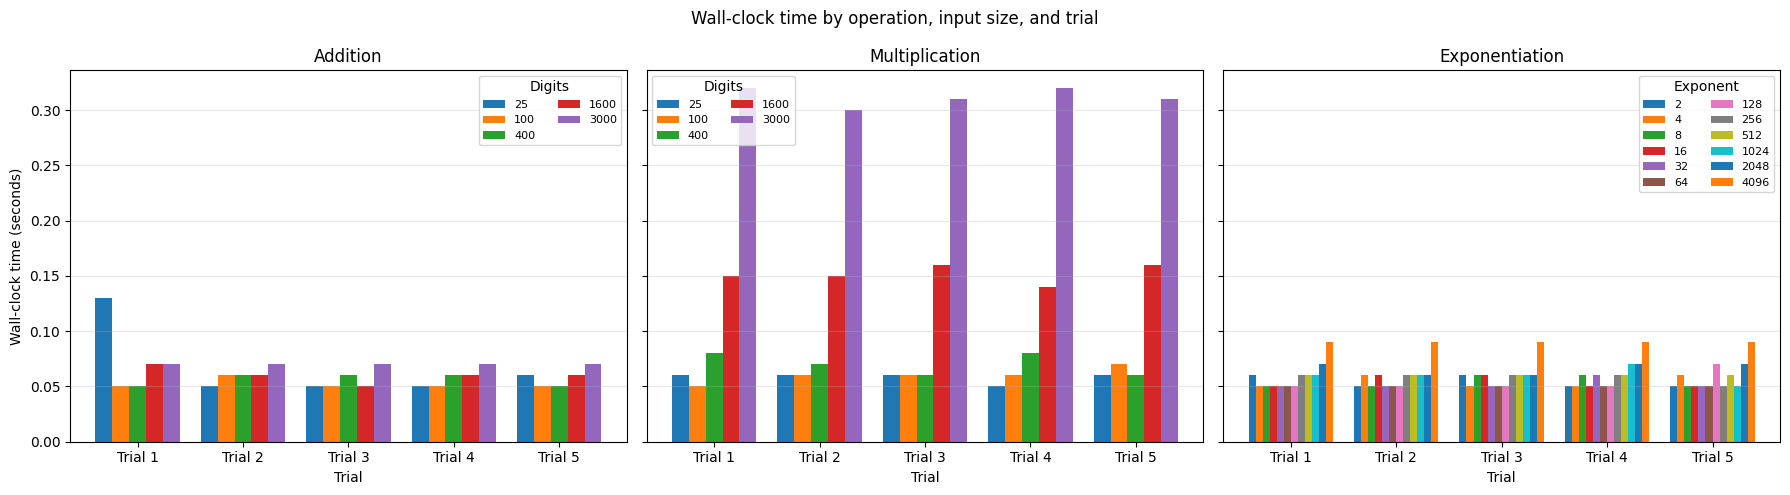

In [3]:
plot_specs = [
    ('add', 'operand_digits', 'Addition', 'Digits'),
    ('multiply', 'operand_digits', 'Multiplication', 'Digits'),
    ('exponentiate', 'exponent', 'Exponentiation', 'Exponent'),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, (operation, scale_column, title, scale_label) in zip(axes, plot_specs):
    subset = df[df['operation'] == operation].copy()
    scales = sorted(subset[scale_column].dropna().unique())
    trials = sorted(subset['trial'].unique())
    width = 0.8 / len(scales)
    positions = range(len(trials))

    for index, scale in enumerate(scales):
        values = subset[subset[scale_column] == scale].sort_values('trial')
        offsets = [x - 0.4 + width / 2 + index * width for x in positions]
        ax.bar(offsets, values['wall_seconds'], width=width,
               label=f'{int(scale)}')

    ax.set_xticks(list(positions), [f'Trial {trial}' for trial in trials])
    ax.set_xlabel('Trial')
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.3)
    ax.legend(title=scale_label, ncols=2, fontsize=8)

axes[0].set_ylabel('Wall-clock time (seconds)')
fig.suptitle('Wall-clock time by operation, input size, and trial')
fig.tight_layout()
plt.show()

### 2-1. Time Complexity of Addition

- **Figure:** Every subplot uses the operand digit length on the x-axis. The first four subplots show the average digit additions, node allocations, traversals, and total counted operations across five trials. The final subplot uses running time in seconds and shows the mean, best, and worst trial.

- **Complexity and variable:** Let `n` and `m` be the two operand digit lengths. Addition is `O(max(n, m))`; for this experiment both operands have `N` digits, so the expected cost is `O(N)`.

- **Evidence:** The digit-additions subplot is exactly 25, 100, 400, 1600, and 3000. The node-allocation, traversal, and total-operation subplots increase by approximately the same factor as `N`, supporting linear growth. Wall-clock time is less clear because fixed JVM startup and system overhead dominate small inputs; the first 25-digit trial is a cold-start outlier.

In [4]:
addition_summary = (
      df[df['operation'] == 'add']
      .groupby('operand_digits')[
          ['digit_adds', 'node_allocs',
           'traversals', 'wall_seconds']
      ]
      .agg(['mean'])
      .reset_index()
      .sort_values('operand_digits')
  )

addition_summary

,operand_digits,digit_adds,node_allocs,traversals,wall_seconds
,,mean,mean,mean,mean
0,25.0,25.0,155.0,313.0,0.068
1,100.0,100.0,605.0,1213.0,0.052
2,400.0,400.0,2403.0,4809.0,0.056
3,1600.0,1600.0,9605.0,19213.0,0.060
4,3000.0,3000.0,18005.0,36013.0,0.070


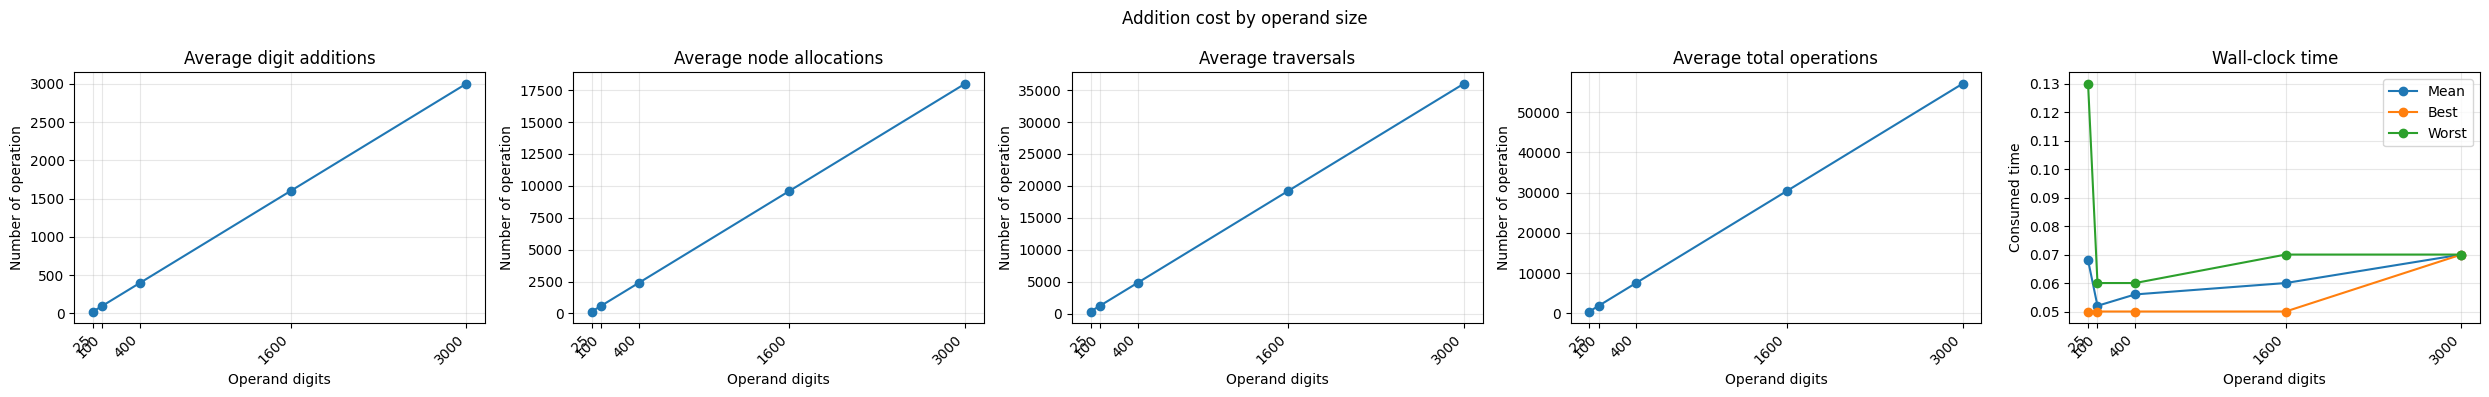

In [5]:
addition_means = (
    df[df['operation'] == 'add']
    .groupby('operand_digits', as_index=False)
    [['digit_adds', 'digit_muls', 'node_allocs', 'traversals', 'wall_seconds']]
    .mean()
    .sort_values('operand_digits')
)
addition_means['total_operations'] = (
    addition_means['digit_adds'] + addition_means['digit_muls']
    + addition_means['node_allocs'] + addition_means['traversals']
)

addition_time_summary = (
    df[df['operation'] == 'add']
    .groupby('operand_digits', as_index=False)['wall_seconds']
    .agg(mean='mean', best='min', worst='max')
    .sort_values('operand_digits')
)

metrics = [
    ('digit_adds', 'Average digit additions'),
    ('node_allocs', 'Average node allocations'),
    ('traversals', 'Average traversals'),
    ('total_operations', 'Average total operations'),
    ('wall_seconds', 'Wall-clock time'),
]

fig, axes = plt.subplots(1, 5, figsize=(25, 4))
for ax, (metric, subplot_title) in zip(axes.flat, metrics):
    if metric == 'wall_seconds':
        ax.plot(addition_time_summary['operand_digits'],
                addition_time_summary['mean'], marker='o', label='Mean')
        ax.plot(addition_time_summary['operand_digits'],
                addition_time_summary['best'], marker='o', label='Best')
        ax.plot(addition_time_summary['operand_digits'],
                addition_time_summary['worst'], marker='o', label='Worst')
        ax.legend()
    else:
        ax.plot(addition_means['operand_digits'], addition_means[metric],
                marker='o')
    ax.set_xticks(addition_means['operand_digits'])
    ax.set_xticklabels(addition_means['operand_digits'].astype(int),
                       rotation=45, ha='right')
    ax.set_xlabel('Operand digits')
    ax.set_title(subplot_title)
    ax.set_ylabel('Consumed time' if metric == 'wall_seconds'
                  else 'Number of operation')
    ax.grid(alpha=0.3)

fig.suptitle('Addition cost by operand size')
fig.tight_layout()
plt.show()

### 2-2. Time Complexity of Multiplication

- **Figure:** Every subplot uses the common operand digit length on the x-axis. The first five subplots show average digit additions, digit multiplications, node allocations, traversals, and total counted operations. The final subplot shows mean, best, and worst running time in seconds.

- **Complexity and variable:** Let `n` and `m` be the digit lengths of the two operands. Grade-school multiplication is `O(nm)`. Because this experiment uses equal-length operands, `n = m = N`, so the expected cost is `O(N^2)`.

- **Evidence:** The digit-multiplications subplot gives 625, 10,000, 160,000, 2,560,000, and 9,000,000, exactly `N^2` at each input size. The remaining counters and total-operations subplot also grow quadratically. The running-time subplot increases most clearly at 1600 and 3000 digits, consistent with the counter evidence.

In [6]:
multiplication_summary = (
      df[df['operation'] == 'multiply']
      .groupby('operand_digits')[
          ['digit_adds', 'digit_muls', 'node_allocs',
           'traversals', 'wall_seconds']
      ]
      .agg(['mean'])
      .reset_index()
      .sort_values('operand_digits')
  )

multiplication_summary

,operand_digits,digit_adds,digit_muls,node_allocs,traversals,wall_seconds
,,mean,mean,mean,mean,mean
0,25.0,1538.0,625.0,2013.0,4523.0,0.058
1,100.0,25025.0,10000.0,30669.0,70271.0,0.060
2,400.0,400047.0,160000.0,482592.0,1096545.0,0.070
3,1600.0,6400306.0,2560000.0,7690420.0,17587910.0,0.152
4,3000.0,22497840.0,9000000.0,27017327.0,61589397.0,0.312


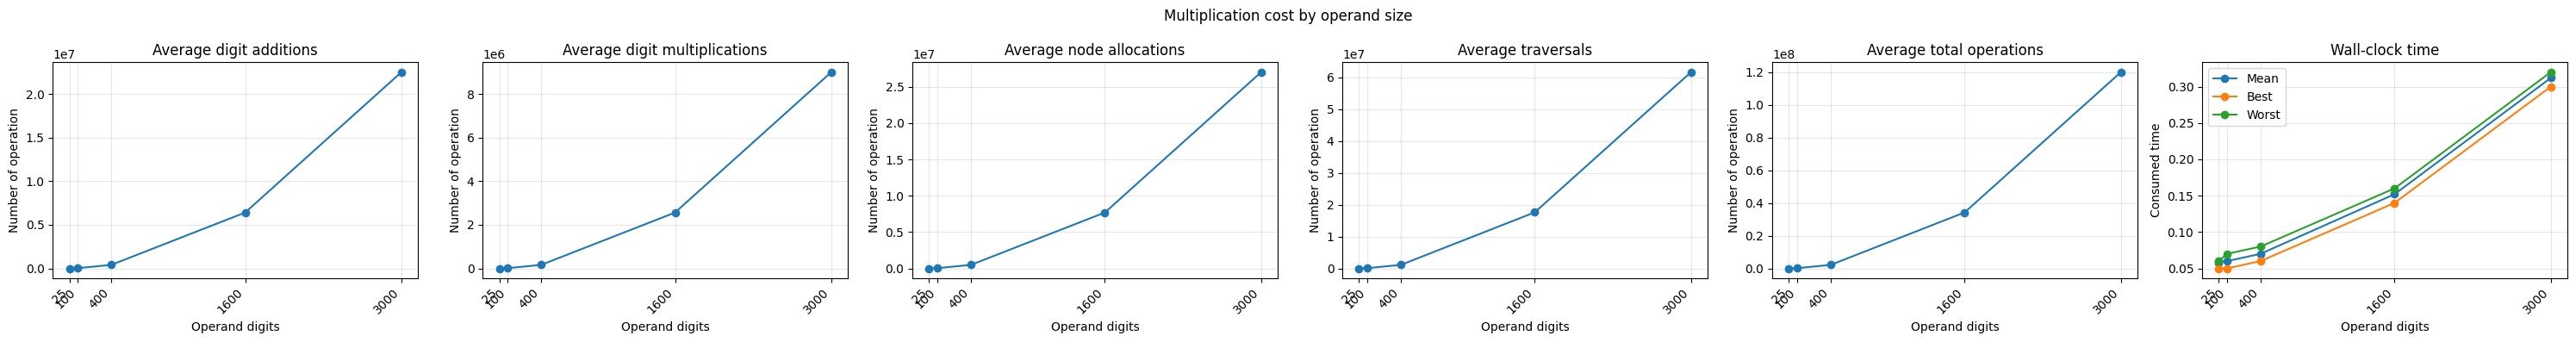

In [7]:
multiplication_means = (
    df[df['operation'] == 'multiply']
    .groupby('operand_digits', as_index=False)
    [['digit_adds', 'digit_muls', 'node_allocs', 'traversals', 'wall_seconds']]
    .mean()
    .sort_values('operand_digits')
)
multiplication_means['total_operations'] = (
    multiplication_means['digit_adds'] + multiplication_means['digit_muls']
    + multiplication_means['node_allocs'] + multiplication_means['traversals']
)

multiplication_time_summary = (
    df[df['operation'] == 'multiply']
    .groupby('operand_digits', as_index=False)['wall_seconds']
    .agg(mean='mean', best='min', worst='max')
    .sort_values('operand_digits')
)

metrics = [
    ('digit_adds', 'Average digit additions'),
    ('digit_muls', 'Average digit multiplications'),
    ('node_allocs', 'Average node allocations'),
    ('traversals', 'Average traversals'),
    ('total_operations', 'Average total operations'),
    ('wall_seconds', 'Wall-clock time'),
]

fig, axes = plt.subplots(1, 6, figsize=(30, 4))
for ax, (metric, subplot_title) in zip(axes.flat, metrics):
    if metric == 'wall_seconds':
        ax.plot(multiplication_time_summary['operand_digits'],
                multiplication_time_summary['mean'], marker='o', label='Mean')
        ax.plot(multiplication_time_summary['operand_digits'],
                multiplication_time_summary['best'], marker='o', label='Best')
        ax.plot(multiplication_time_summary['operand_digits'],
                multiplication_time_summary['worst'], marker='o', label='Worst')
        ax.legend()
    else:
        ax.plot(multiplication_means['operand_digits'],
                multiplication_means[metric], marker='o')
    ax.set_xticks(multiplication_means['operand_digits'])
    ax.set_xticklabels(multiplication_means['operand_digits'].astype(int),
                       rotation=45, ha='right')
    ax.set_xlabel('Operand digits')
    ax.set_title(subplot_title)
    ax.set_ylabel('Consumed time' if metric == 'wall_seconds'
                  else 'Number of operation')
    ax.grid(alpha=0.3)

fig.suptitle('Multiplication cost by operand size')
fig.tight_layout()
plt.show()

### 2-3. Time Complexity of Exponentiation

- **Figure:**
    - The first figure uses the actual exponent `e` (`2, 4, 8, ..., 4096`) on a log-scale x-axis.
    - The second figure uses `N`, the number of decimal digits in one operand of the final squaring step, `2^(e / 2) * 2^(e / 2)`.
    - In both figures, the first five subplots show mean counter values across five trials. The final subplot shows mean, best, and worst consumed time.

- **Complexity and variable:**
    - Exponentiation by squaring repeatedly halves `e`. Therefore, its control flow has `O(log e)` multiplication levels. The first figure shows the measured cost while `e` doubles at every x-axis step. Although the number of levels grows slowly, the measured counters grow rapidly. Thus, `O(log e)` levels do not mean that the digit-level cost is `O(log e)`.
    - To explain this growth, the second figure rewrites the same measurements using `N`, the digit length of the operands in the final and largest multiplication. The multiplication experiment showed that grade-school multiplication costs `O(N^2)`. The final multiplication is the largest and dominates the smaller earlier multiplications, so exponentiation has measured digit-level cost `O(N^2)`.
    - The base is fixed at 2, so `N` grows proportionally to the numerical exponent `e`. Therefore, `O(N^2)` is equivalently `O(e^2)` in this experiment.

In [8]:
exponentiation_summary = (
      df[df['operation'] == 'exponentiate']
      .groupby('exponent')[
          ['digit_adds', 'digit_muls', 'node_allocs',
           'traversals', 'wall_seconds']
      ]
      .agg(['mean'])
      .reset_index()
      .sort_values('exponent')
  )

exponentiation_summary

,exponent,digit_adds,digit_muls,node_allocs,traversals,wall_seconds
,,mean,mean,mean,mean,mean
0,2.0,2.0,1.0,11.0,24.0,0.054
1,4.0,5.0,2.0,18.0,39.0,0.054
2,8.0,14.0,6.0,31.0,71.0,0.054
3,16.0,37.0,15.0,64.0,150.0,0.054
4,32.0,102.0,40.0,151.0,357.0,0.052
5,64.0,355.0,140.0,471.0,1115.0,0.050
6,128.0,1353.0,540.0,1692.0,3933.0,0.054
7,256.0,5164.0,2061.0,6317.0,14581.0,0.058
8,512.0,20340.0,8145.0,24599.0,56319.0,0.060


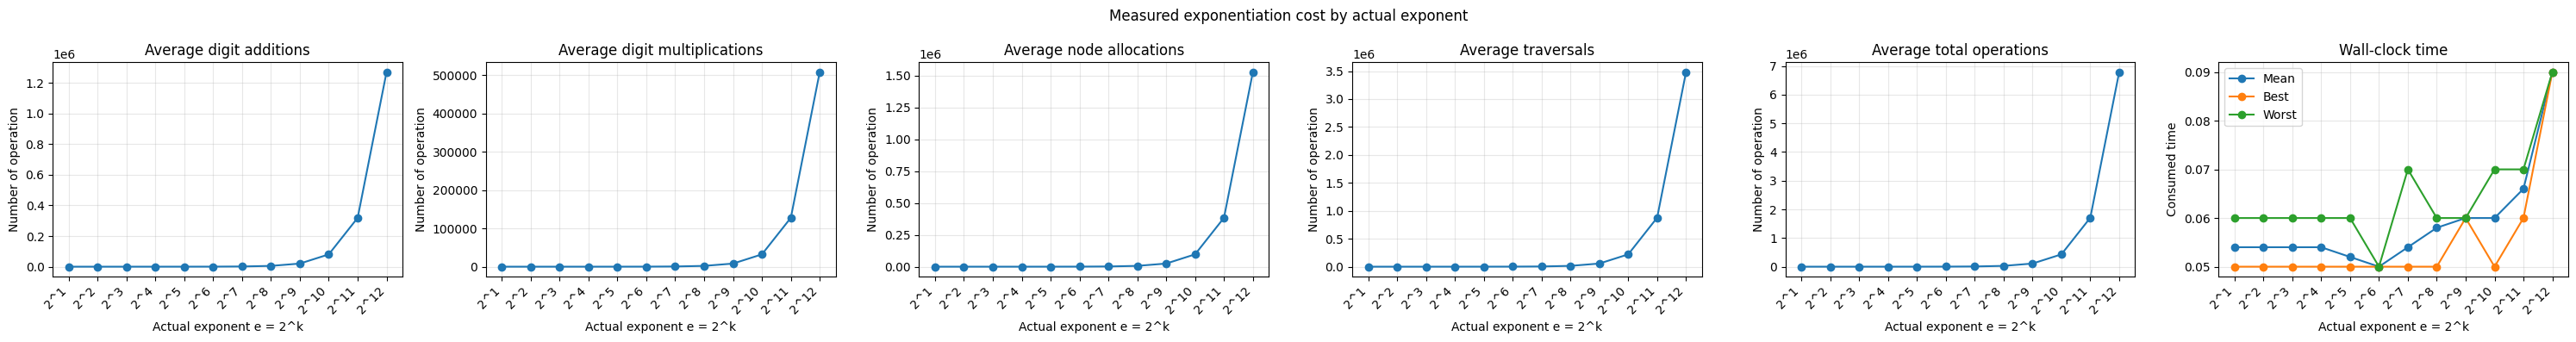

In [13]:
# This plot uses the measured counters and wall-clock times in measurements.csv.
exponentiation_means = (
    df[df['operation'] == 'exponentiate']
    .groupby('exponent', as_index=False)
    [['digit_adds', 'digit_muls', 'node_allocs', 'traversals', 'wall_seconds']]
    .mean()
    .sort_values('exponent')
)
exponentiation_means['total_operations'] = (
    exponentiation_means['digit_adds'] + exponentiation_means['digit_muls']
    + exponentiation_means['node_allocs'] + exponentiation_means['traversals']
)

exponentiation_time_summary = (
    df[df['operation'] == 'exponentiate']
    .groupby('exponent', as_index=False)['wall_seconds']
    .agg(mean='mean', best='min', worst='max')
    .sort_values('exponent')
)

metrics = [
    ('digit_adds', 'Average digit additions'),
    ('digit_muls', 'Average digit multiplications'),
    ('node_allocs', 'Average node allocations'),
    ('traversals', 'Average traversals'),
    ('total_operations', 'Average total operations'),
    ('wall_seconds', 'Wall-clock time'),
]

fig, axes = plt.subplots(1, 6, figsize=(30, 4))
for ax, (metric, subplot_title) in zip(axes.flat, metrics):
    if metric == 'wall_seconds':
        ax.plot(exponentiation_time_summary['exponent'],
                exponentiation_time_summary['mean'], marker='o', label='Mean')
        ax.plot(exponentiation_time_summary['exponent'],
                exponentiation_time_summary['best'], marker='o', label='Best')
        ax.plot(exponentiation_time_summary['exponent'],
                exponentiation_time_summary['worst'], marker='o', label='Worst')
        ax.legend()
    else:
        ax.plot(exponentiation_means['exponent'],
                exponentiation_means[metric], marker='o')
    ax.set_xscale('log', base=2)
    ax.set_xticks(exponentiation_means['exponent'])
    ax.set_xticklabels(exponentiation_means['exponent'].astype(int),
                       rotation=45, ha='right')
    ax.set_xlabel('Actual exponent e')
    ax.set_title(subplot_title)
    ax.set_ylabel('Consumed time' if metric == 'wall_seconds'
                  else 'Number of operation')
    ax.grid(alpha=0.3)

fig.suptitle('Measured exponentiation cost by actual exponent')
fig.tight_layout()
plt.show()

,exponent,final_factor_digits
9,1024.0,155


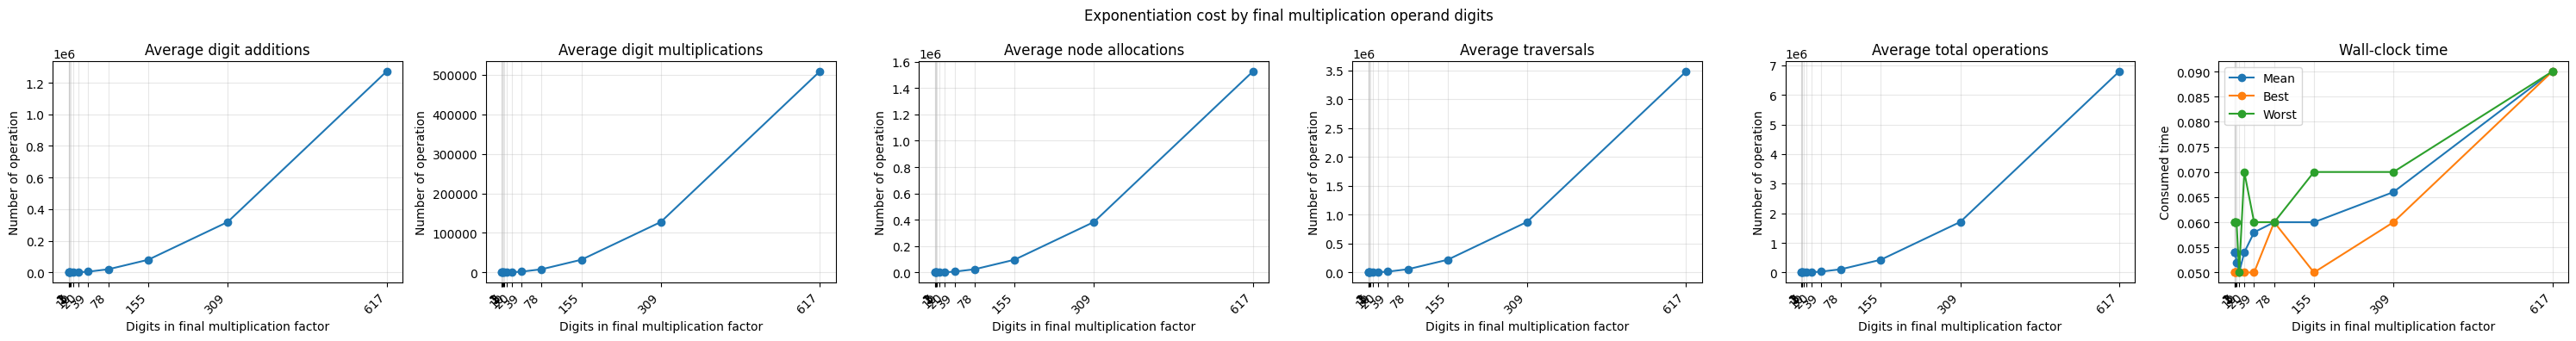

In [11]:
# For exponent e, the final squaring is 2^(e / 2) * 2^(e / 2).
# This x-axis is the digit length of either factor in that final multiplication.
from math import floor, log10

exponentiation_means = (
    df[df['operation'] == 'exponentiate']
    .groupby('exponent', as_index=False)
    [['digit_adds', 'digit_muls', 'node_allocs', 'traversals', 'wall_seconds']]
    .mean()
    .sort_values('exponent')
)
exponentiation_means['total_operations'] = (
    exponentiation_means['digit_adds'] + exponentiation_means['digit_muls']
    + exponentiation_means['node_allocs'] + exponentiation_means['traversals']
)

exponentiation_time_summary = (
    df[df['operation'] == 'exponentiate']
    .groupby('exponent', as_index=False)['wall_seconds']
    .agg(mean='mean', best='min', worst='max')
    .sort_values('exponent')
)

exponentiation_digit_view = exponentiation_means.copy()
exponentiation_digit_view['final_factor_digits'] = (
    exponentiation_digit_view['exponent'].map(
        lambda e: floor((e / 2) * log10(2)) + 1
    )
)

exponentiation_digit_time = exponentiation_time_summary.copy()
exponentiation_digit_time['final_factor_digits'] = (
    exponentiation_digit_time['exponent'].map(
        lambda e: floor((e / 2) * log10(2)) + 1
    )
)

# At e = 1024, the final multiplication is 2^512 * 2^512.
example_e1024 = exponentiation_digit_view[
    exponentiation_digit_view['exponent'] == 1024
][['exponent', 'final_factor_digits']]
display(example_e1024)

metrics = [
    ('digit_adds', 'Average digit additions'),
    ('digit_muls', 'Average digit multiplications'),
    ('node_allocs', 'Average node allocations'),
    ('traversals', 'Average traversals'),
    ('total_operations', 'Average total operations'),
    ('wall_seconds', 'Wall-clock time'),
]

fig, axes = plt.subplots(1, 6, figsize=(30, 4))
for ax, (metric, subplot_title) in zip(axes.flat, metrics):
    if metric == 'wall_seconds':
        ax.plot(exponentiation_digit_time['final_factor_digits'],
                exponentiation_digit_time['mean'], marker='o', label='Mean')
        ax.plot(exponentiation_digit_time['final_factor_digits'],
                exponentiation_digit_time['best'], marker='o', label='Best')
        ax.plot(exponentiation_digit_time['final_factor_digits'],
                exponentiation_digit_time['worst'], marker='o', label='Worst')
        ax.legend()
    else:
        ax.plot(exponentiation_digit_view['final_factor_digits'],
                exponentiation_digit_view[metric], marker='o')
    ax.set_xticks(exponentiation_digit_view['final_factor_digits'])
    ax.set_xticklabels(exponentiation_digit_view['final_factor_digits'],
                       rotation=45, ha='right')
    ax.set_xlabel('Digits in final multiplication factor')
    ax.set_title(subplot_title)
    ax.set_ylabel('Consumed time' if metric == 'wall_seconds'
                  else 'Number of operation')
    ax.grid(alpha=0.3)

fig.suptitle('Exponentiation cost by final multiplication operand digits')
fig.tight_layout()
plt.show()